# RQ1 Part B: why did inflation change in 2022?

- Part A found a new regime from Aug 2022 (average 0.50% before, 2.99% after).
- Part B asks why: we check three reasons from earlier research against the data.
- No new tests: one table and one chart.

In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# The project folder, whether the notebook runs from notebooks/ or from the project folder
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES = ROOT / "results" / "tables"
FIGURES = ROOT / "results" / "figures"

dataset = pd.read_csv(ROOT / "data" / "processed" / "dataset.csv", index_col="month")
regimes = pd.read_csv(TABLES / "rq1_regimes.csv")

## 1. Three reasons

| Reason | If true, we should see |
|---|---|
| 1. Imported costs (weak yen, energy, food) | Inflation falls when import prices fall |
| 2. Firms' price-setting changed | Price plans and expectations stay high after import prices fall |
| 3. Wages and prices | Wages rise from 2023, then service firms' price plans rise |

These predictions were written in October, before this notebook was run.

## 2. Three periods

Before vs after alone cannot separate the reasons, because in 2022 everything rose together. They only differ **after import prices fall**, so we split "after" at that month:

| Period | From | To |
|---|---|---|
| Before | Start of the regime before the break | Month before the break |
| After, costs rising | The break | Month before import prices first fall |
| After, costs eased | First month import prices fall | End of the data |

# "Costs" here means **import costs** only. Wages kept rising (reason 3).

The code finds every date in two steps.

### Step 1: the break, from Part A

The last regime is "after". The one before it is "before" (the earlier regimes are the deflation years, so we leave them out).

In [9]:
level = regimes[regimes["series"] == "level"]
before_start = level["start"].iloc[-2]
before_end = level["end"].iloc[-2]
after_start = level["start"].iloc[-1]
data_end = level["end"].iloc[-1]

print("Before:", before_start, "to", before_end)
print("After: ", after_start, "to", data_end)
level[["regime", "start", "end", "months", "average"]]

Before: 2013-07 to 2022-07
After:  2022-08 to 2026-08


,regime,start,end,months,average
0,1,2007-01,2009-12,36,0.11
1,2,2010-01,2013-06,42,-0.79
2,3,2013-07,2022-07,109,0.50
3,4,2022-08,2026-08,49,2.99


### Step 2: the first month import prices fall

Import prices (% YoY) from the break on. The first negative value is the first fall.

In [10]:
imports = dataset.loc[after_start:, "c2_import_prices"]
first_fall = imports[imports < 0].index[0]
last_rise = imports[imports.index < first_fall].index[-1]

print("First month with import prices below a year earlier:", first_fall)
imports.loc[:first_fall]

First month with import prices below a year earlier: 2023-04


month
2022-08    43.1419
2022-09    48.7018
2022-10    42.2642
2022-11    27.9570
2022-12    22.1664
2023-01    16.8822
2023-02    14.9965
2023-03     9.3433
2023-04    -3.6855
Name: c2_import_prices, dtype: float64

### The three periods

In [11]:
periods = {
    "Before": (before_start, before_end),
    "After, costs rising": (after_start, last_rise),
    "After, costs eased": (first_fall, data_end),
}
for name in periods:
    print(name, ":", periods[name][0], "to", periods[name][1])

Before : 2013-07 to 2022-07
After, costs rising : 2022-08 to 2023-03
After, costs eased : 2023-04 to 2026-08


## 3. Table: average of each indicator in each period

- Read each row left to right: up after the break? Still high after costs eased?
- The number before each indicator is its reason (1, 2 or 3).
- Tankan and diffusion index: % rising minus % falling.

In [12]:
# Column name -> label (the number is the reason it belongs to)
labels = {
    "target": "Target inflation (%)",
    "c2_import_prices": "1. Import prices (% YoY)",
    "c6_diffusion": "2. CPI diffusion index",
    "c6_tankan_all": "2. Tankan price plans, all firms",
    "c1_hh_expect_mean": "2. Household expectations, 1 year (%)",
    "c5_shunto": "3. Shunto wage settlement (%)",
    "c5_earnings": "3. Total cash earnings (% YoY)",
    "c6_tankan_small_services": "3. Tankan price plans, small service firms",
}

table = pd.DataFrame()
for name in periods:
    start, end = periods[name]
    table[name] = dataset.loc[start:end, list(labels)].mean()
table = table.rename(index=labels).round(1)
table.index.name = "indicator"
table

,Before,"After, costs rising","After, costs eased"
indicator,,,
Target inflation (%),0.5,3.0,3.0
1. Import prices (% YoY),3.8,28.2,1.0
2. CPI diffusion index,22.1,64.7,63.1
"2. Tankan price plans, all firms",0.4,33.4,32.7
"2. Household expectations, 1 year (%)",4.4,9.2,11.3
3. Shunto wage settlement (%),2.1,2.2,4.6
3. Total cash earnings (% YoY),0.3,1.8,2.3
"3. Tankan price plans, small service firms",0.5,30.5,33.3


## 4. Chart: each indicator over time

- Shows the order of events, which the averages hide (needed for reason 3).
- Dashed line: the break. Grey area: after costs eased.

Source: Bank of Japan; Statistics Bureau of Japan; Ministry of Health, Labour and Welfare.

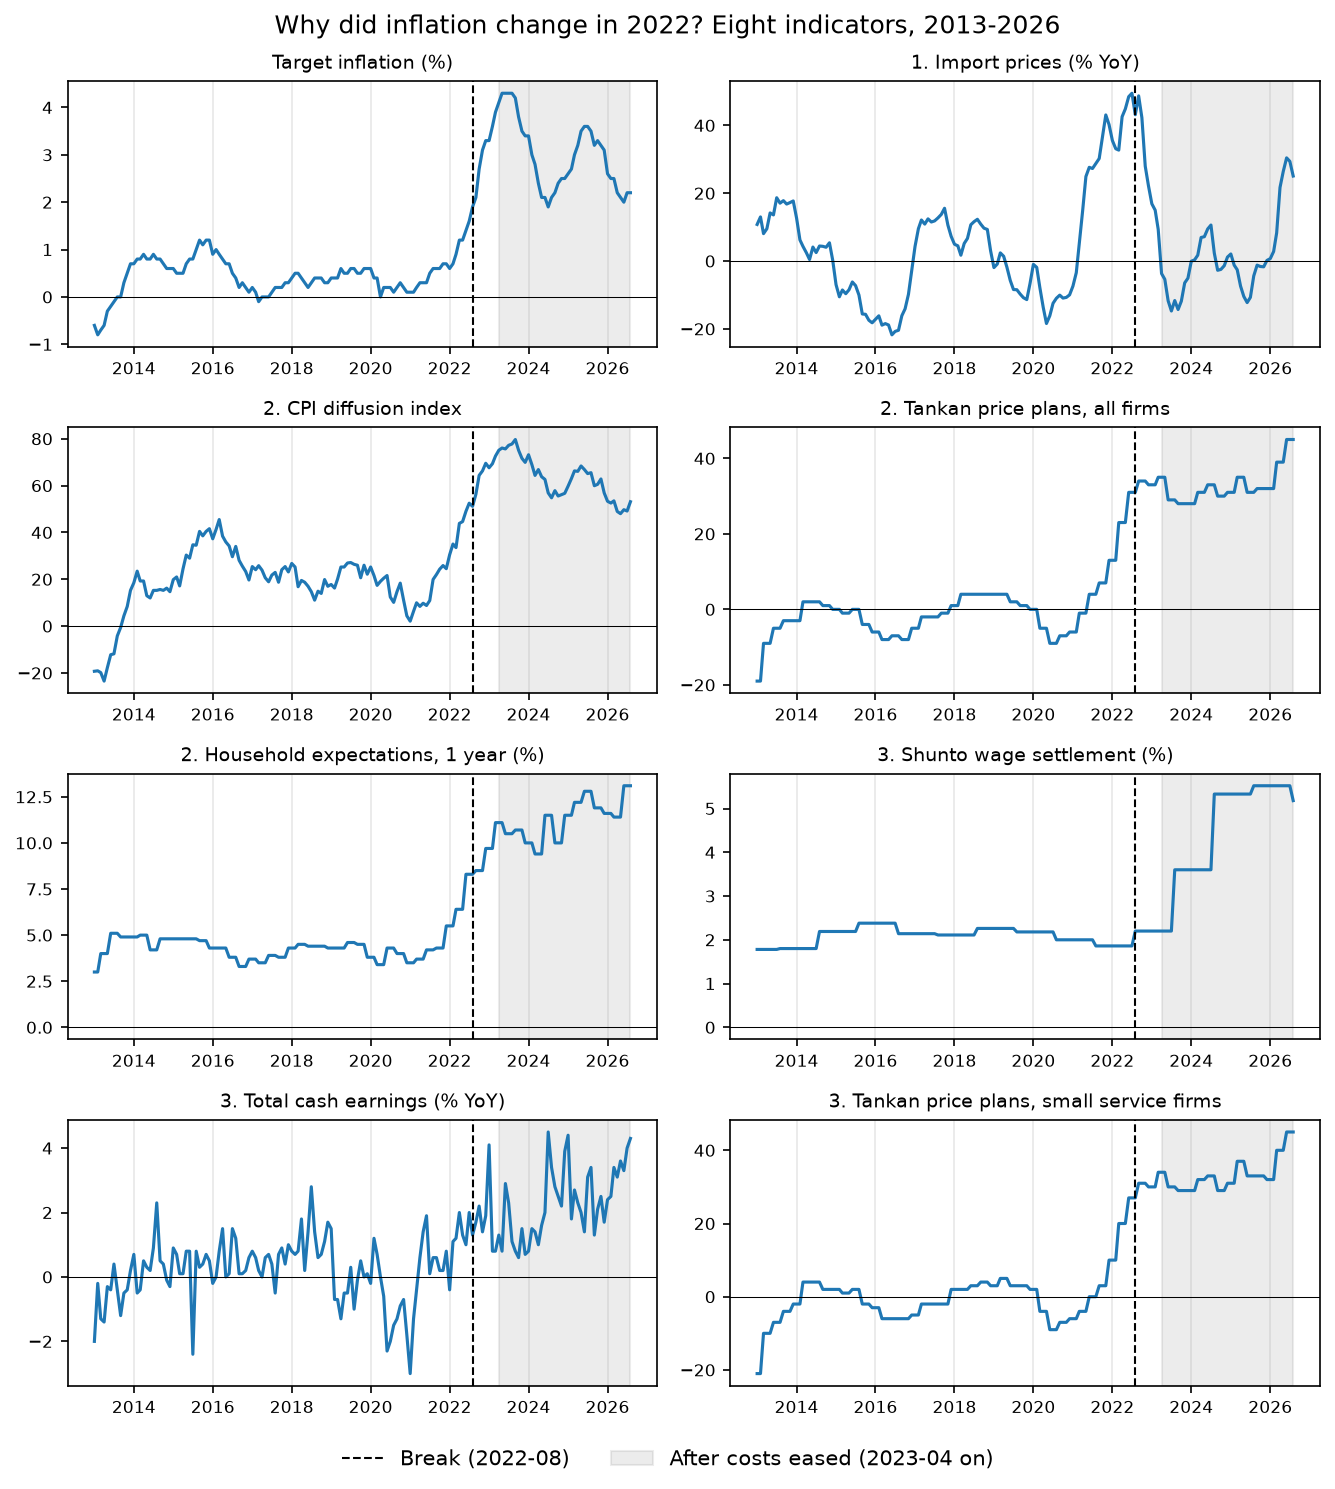

In [15]:
data = dataset.loc["2013-01":]
dates = pd.to_datetime(data.index)

fig, axes = plt.subplots(4, 2, figsize=(9, 10), dpi=150, sharex=True)
for ax, column in zip(axes.flat, labels):
    ax.plot(dates, data[column], color="tab:blue")
    ax.axvline(pd.Timestamp(after_start), color="black", linestyle="--", linewidth=1,
               label=f"Break ({after_start})")
    ax.axvspan(pd.Timestamp(first_fall), dates[-1], color="gray", alpha=0.15,
               label=f"After costs eased ({first_fall} on)")
    ax.axhline(0, color="black", linewidth=0.5)
    ax.set_title(labels[column], fontsize=9)
    ax.tick_params(labelbottom=True, labelsize=8)  # years under every panel
    ax.grid(axis="x", alpha=0.3)
fig.suptitle("Why did inflation change in 2022? Eight indicators, 2013-2026")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## 5. Save the table and the chart

In [14]:
table.to_csv(TABLES / "rq1_explanations.csv")
fig.savefig(FIGURES / "rq1_explanations.png")
print("Saved results/tables/rq1_explanations.csv and results/figures/rq1_explanations.png")

Saved results/tables/rq1_explanations.csv and results/figures/rq1_explanations.png


## 6. Verdict

| Reason | Question | Answer | Verdict |
|---|---|---|---|
| 1. Imported costs | When import prices fell, did inflation fall? | Only partly. Import prices rose first (from 2021, peak Jul 2022) and inflation peaked about 10 months later (May 2023). But after import prices fell (28.2 to 1.0), inflation's average stayed at 3.0, far above 0.5 before | Partly consistent |
| 2. Price-setting | After costs eased, did price plans and expectations stay high? | Yes. Tankan price plans stayed around 33, household expectations rose further (9.2 to 11.3), and the diffusion index stayed near 63 | Consistent |
| 3. Wages and prices | Did wages rise first, and service firms' price plans after? | No, the order is reversed. Service firms' price plans jumped in 2022 (0.5 to 30.5) while Shunto was still 2.2. Wages rose only in 2023-24 (Shunto 4.6 on average). Earnings grew 1.8-2.3% a year while inflation was 3.0%, so real wages fell | Partly consistent |

**Summary:** imported costs started the 2022 rise; a change in firms' and households' price behaviour kept inflation high; wages followed later. This is consistent with a new inflation regime so far.

Limits: this is a comparison of averages, not a test. The "costs rising" period is only 8 months, and the CPI diffusion index is built from the same CPI items as inflation, so it is weaker evidence than the surveys.